# 4 · Historical crashes and single-coin shocks

For each actual market crash we ask:

* how much each strategy lost, and how long it took to recover;
* whether the **spreads** that pairs traders bet on returned toward equilibrium afterwards;
* whether the GARCH filter switched on in time.

We then study two real **single-coin shocks** in this universe, where one coin moved violently while its partners did not:

* **XMR, February 2024:** Binance announced on 6 Feb 2024 that it would delist Monero.
* **ZEC, October–November 2025:** Zcash rose more than tenfold in about eight weeks while the rest of the market fell.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from cryptopairs import plotting as P
from cryptopairs.project import setup, run_three, START
from cryptopairs.data import ORDER
from cryptopairs.dynamic import ordered_pairs, ou_fit
from cryptopairs.stats import ols_hedge
from cryptopairs.risk import EVENTS, recovery_days, high_vol_regime
P.set_style()
pd.set_option("display.precision", 4, "display.width", 180, "display.max_columns", 30)
px, vol, mkt, sig, risk_off = setup()
res = run_three(px, vol, risk_off)
lp = np.log(px)
end = px.index[-1]

## 1. Strategy outcomes in each crash window

*Worst point* is the lowest equity inside the window relative to the day before it. *Recovery* counts the days from the start of the window until equity first gets back to that pre-window level (0 = it never fell below during the window; "not yet" = still below on 23 May 2026).

In [2]:
rows = []
for ev, (a, b) in EVENTS.items():
    a, b = pd.Timestamp(a), pd.Timestamp(b)
    for n, r in res.items():
        ret, t = r["returns"], r["trades"]
        seg = ret.loc[a:b]
        nav = (1 + seg).cumprod()
        worst = min(nav.min() - 1, 0.0)
        days = 0
        if worst < -1e-9:
            after = (1 + ret.loc[a:]).cumprod()
            back = after[(after.index > nav.idxmin()) & (after >= 1 - 1e-9)]
            days = (back.index[0] - a).days if len(back) else np.nan
        rows.append({"event": ev, "strategy": n,
                     "return in window": nav.iloc[-1] - 1,
                     "worst point in window": worst,
                     "trades open at start": int(((t.entry < a) & (t.exit >= a)).sum()),
                     "trades opened in window": int(t.entry.between(a, b).sum()),
                     "days invested": int((seg != 0).sum()),
                     "recovery (days)": ("not yet" if pd.isna(days) else int(days)),
                     "risk-off share": risk_off.loc[a:b].mean() if n == "Dynamic + GARCH" else np.nan})
crash = pd.DataFrame(rows).set_index(["event", "strategy"])
crash

return in window  worst point in window  trades open at start  trades opened in window  days invested  recovery (days)  risk-off share
event                   strategy                                                                                                                                               
COVID crash (Mar 2020)  Static                    -0.0049                -0.0052                     1                        0             23              164             NaN
                        Dynamic                    0.0000                 0.0000                     0                        0              0                0             NaN
                        Dynamic + GARCH            0.0000                 0.0000                     0                        0              0                0          0.9677
May 2021 crash          Static                     0.0000                 0.0000                     0                        0              0                0             NaN
                        Dynamic                    0.0156                -0.0001                     0                        1              4               15             NaN
                        Dynamic + GARCH            0.0000                 0.0000                     0                        0              0                0          0.8387
Terra/LUNA (May 2022)   Static                    -0.0082                -0.0132                     3                        2             31               33             NaN
                        Dynamic                    0.0050                 0.0000                     1                        1             15                0             NaN
                        Dynamic + GARCH            0.0041                 0.0000                     1                        0              1                0          0.4839
FTX collapse (Nov 2022) Static                    -0.0087                -0.0087                     0                        1             14              232             NaN
                        Dynamic                    0.0091                -0.0128                     0                        3             23               20             NaN
                        Dynamic + GARCH            0.0200                -0.0001                     0                        2             15               17          0.3548
Oct 2025 liquidations   Static                     0.0000                 0.0000                     0                        0              0                0             NaN
                        Dynamic                    0.0000                 0.0000                     0                        0              0                0             NaN
                        Dynamic + GARCH            0.0000                 0.0000                     0                        0              0                0          0.2581

In [3]:
for n, r in res.items():
    t = r["trades"]
    for ev, (a, b) in EVENTS.items():
        sel = t[(t.entry <= pd.Timestamp(b)) & (t.exit >= pd.Timestamp(a))]
        if len(sel):
            print(f"{n:16s} | {ev:24s} | " + "; ".join(
                f"{row.A}~{row.B} {row.entry.date()}->{row.exit.date()} {row.ret:+.1%} ({row.reason})"
                for row in sel.itertuples()))

Static           | COVID crash (Mar 2020)   | BNB~BCH 2020-01-15->2020-03-30 +2.7% (window_end)
Static           | Terra/LUNA (May 2022)    | LINK~XLM 2022-05-01->2022-05-13 -7.8% (stop); XLM~LTC 2022-06-01->2022-06-18 -3.0% (window_end); XMR~BCH 2022-05-15->2022-05-18 +0.4% (stop); LINK~LTC 2022-05-01->2022-06-09 +10.3% (revert); LINK~TRX 2022-04-22->2022-05-05 -16.2% (stop)
Static           | FTX collapse (Nov 2022)  | XLM~LTC 2022-11-05->2022-11-18 -6.9% (stop)
Dynamic          | May 2021 crash           | LINK~XLM 2021-05-24->2021-05-27 +12.6% (revert)
Dynamic          | Terra/LUNA (May 2022)    | BNB~BCH 2022-05-22->2022-06-06 +1.0% (time_stop); BNB~TRX 2022-05-03->2022-05-05 -2.6% (stop)
Dynamic          | FTX collapse (Nov 2022)  | LINK~LTC 2022-11-14->2022-12-03 -2.7% (time_stop); LINK~BNB 2022-11-13->2022-11-26 +6.6% (time_stop); LINK~XLM 2022-12-01->2022-12-21 +8.6% (time_stop)
Dynamic + GARCH  | Terra/LUNA (May 2022)    | BNB~TRX 2022-05-03->2022-05-05 -2.6% (stop)
Dynamic +

## 2. Did the spreads revert?

This part does not depend on any strategy's entry decisions. For every one of the 28 pairs and every crash, fit the dynamic model (180-day OLS hedge ratio and OU fit) on the data available **the day before the window**, then follow that frozen spread. We record the widest deviation during the window, in OU equilibrium standard deviations, and whether the spread came back within 0.5 s.d. of its OU mean within 60 days after the window ended. As a benchmark we run the same calculation on 30-day windows that start every 30 days outside the crash periods.

In [4]:
PAIRS = ordered_pairs(ORDER)
def spread_episode(a, b, y, x):
    hist = lp.loc[a - pd.Timedelta(days=180):a - pd.Timedelta(days=1)]
    al, be = ols_hedge(hist[y], hist[x])
    ou = ou_fit((hist[y] - be * hist[x] - al).to_numpy())
    z = (lp[y] - be * lp[x] - al - ou["mu"]) / ou["sigma_eq"]
    win = z.loc[a:b]
    after = z.loc[b + pd.Timedelta(days=1):b + pd.Timedelta(days=60)]
    peak = win.abs().max()
    return {"max |z| in window": peak, "beyond 2 sd": peak >= 2, "beyond 4 sd": peak >= 4,
            "back within 0.5 sd in 60 days": bool((after.abs() < 0.5).any()) if len(after) else np.nan,
            "half-life before (days)": ou["half_life"]}
recs = []
for ev, (a, b) in EVENTS.items():
    for y, x in PAIRS:
        recs.append({"period": ev, "pair": f"{y}~{x}", **spread_episode(pd.Timestamp(a), pd.Timestamp(b), y, x)})
from cryptopairs.risk import event_mask
calm_starts = [d for d in pd.date_range("2020-02-01", end - pd.Timedelta(days=100), freq="30D")
               if not event_mask(pd.date_range(d, d + pd.Timedelta(days=30))).any()]
for d in calm_starts:
    for y, x in PAIRS:
        recs.append({"period": "other 30-day windows", "pair": f"{y}~{x}",
                     **spread_episode(d, d + pd.Timedelta(days=30), y, x)})
sp = pd.DataFrame(recs)
sp_sum = sp.groupby("period", sort=False).agg(**{
    "pair-windows": ("pair", "size"), "median max |z|": ("max |z| in window", "median"),
    "share beyond 2 sd": ("beyond 2 sd", "mean"), "share beyond 4 sd": ("beyond 4 sd", "mean"),
    "share back within 60 days": ("back within 0.5 sd in 60 days", "mean")})
sp_sum

,pair-windows,median max |z|,share beyond 2 sd,share beyond 4 sd,share back within 60 days
period,,,,,
COVID crash (Mar 2020),28,2.2040,0.6071,0.0357,0.7857
May 2021 crash,28,1.5594,0.2143,0.0000,0.5000
Terra/LUNA (May 2022),28,2.4316,0.6429,0.1786,0.5714
FTX collapse (Nov 2022),28,2.9123,0.7857,0.3571,0.4286
Oct 2025 liquidations,28,1.6628,0.2500,0.0357,0.3571
other 30-day windows,1792,1.9863,0.4911,0.1468,0.6133


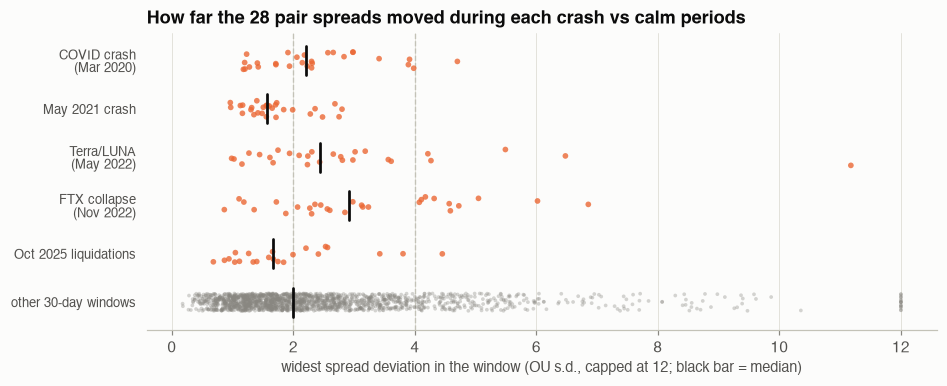

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 3.4))
order_ = list(EVENTS) + ["other 30-day windows"]
for i, per in enumerate(order_):
    v = sp.loc[sp.period == per, "max |z| in window"].clip(upper=12)
    jit = np.random.default_rng(i).uniform(-0.18, 0.18, len(v))
    col = P.C[1] if per in EVENTS else P.MUTED
    ax.scatter(v, i + jit, s=14 if per in EVENTS else 6, color=col, alpha=0.8 if per in EVENTS else 0.35,
               edgecolor="none", zorder=3)
    ax.plot([v.median()] * 2, [i - 0.3, i + 0.3], color=P.INK, lw=1.8, zorder=4)
ax.axvline(2, color=P.AXIS, lw=0.9, ls="--"); ax.axvline(4, color=P.AXIS, lw=0.9, ls="--")
ax.set_yticks(range(len(order_)), [o.replace(" (", "\n(") for o in order_], fontsize=8.5)
ax.grid(axis="x"); ax.grid(axis="y", visible=False); ax.invert_yaxis()
ax.set_xlabel("widest spread deviation in the window (OU s.d., capped at 12; black bar = median)")
ax.set_title("How far the 28 pair spreads moved during each crash vs calm periods")
P.save(fig, "04_spread_deviation")

## 3. Single-coin shocks: XMR delisting (Feb 2024) and ZEC surge (Oct–Nov 2025)

The lines below are hypothetical diagnostics. For each case the chart shows every pair containing the shocked coin, including pairs that had not passed the cointegration screen, with the spread frozen at a 180-day OLS and OU fit from the day before the shock. The y-axis is in OU equilibrium standard deviations. None of the three strategies held an XMR pair or a ZEC pair in the fortnights drawn here. The GARCH flag is a forecast of the mean log return. It does not monitor each spread.

XMR delisting (Feb 2024): XMR -31% over two weeks vs median +15% for the other seven coins; filter risk-off on 21% of those days
   widest spread deviation across the 7 XMR pairs: median 10.3 s.d., max 14.9 s.d.
   Static          : no trade in a XMR pair
   Dynamic         : no trade in a XMR pair
   Dynamic + GARCH : no trade in a XMR pair
ZEC surge (Oct-Nov 2025): ZEC +324% over two weeks vs median -4% for the other seven coins; filter risk-off on 50% of those days
   widest spread deviation across the 7 ZEC pairs: median 15.9 s.d., max 18.3 s.d.
   Static          : no trade in a ZEC pair
   Dynamic         : no trade in a ZEC pair
   Dynamic + GARCH : no trade in a ZEC pair


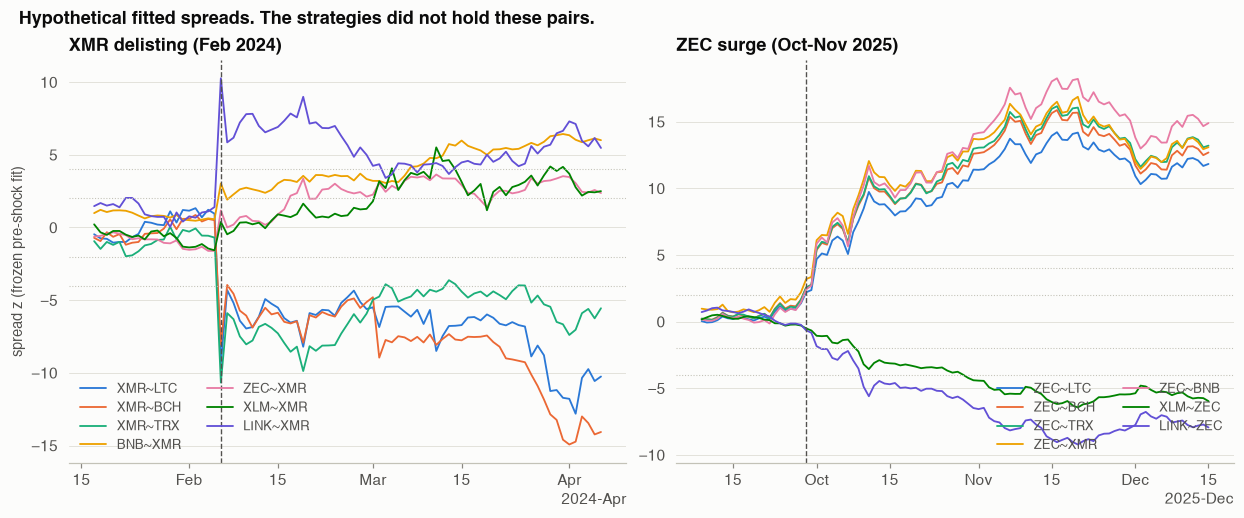

In [6]:
CASES = {"XMR delisting (Feb 2024)": ("XMR", pd.Timestamp("2024-02-06"), pd.Timestamp("2024-04-06")),
         "ZEC surge (Oct-Nov 2025)": ("ZEC", pd.Timestamp("2025-09-29"), pd.Timestamp("2025-12-15"))}
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.6), sharey=False)
for ax, (case, (coin, a, b)) in zip(axes, CASES.items()):
    others = px.drop(columns=coin).loc[a - pd.Timedelta(days=1):a + pd.Timedelta(days=13)]
    move = px[coin][a + pd.Timedelta(days=13)] / px[coin][a - pd.Timedelta(days=1)] - 1
    rest = (others.iloc[-1] / others.iloc[0] - 1).median()
    print(f"{case}: {coin} {move:+.0%} over two weeks vs median {rest:+.0%} for the other seven coins; "
          f"filter risk-off on {risk_off.loc[a:a + pd.Timedelta(days=13)].mean():.0%} of those days")
    pairs = [(y, x) for y, x in PAIRS if coin in (y, x)]
    zmax = []
    for i, (y, x) in enumerate(pairs):
        hist = lp.loc[a - pd.Timedelta(days=180):a - pd.Timedelta(days=1)]
        al, be = ols_hedge(hist[y], hist[x]); ou = ou_fit((hist[y] - be * hist[x] - al).to_numpy())
        z = ((lp[y] - be * lp[x] - al - ou["mu"]) / ou["sigma_eq"]).loc[a - pd.Timedelta(days=20):b]
        zmax.append(z.loc[a:].abs().max())
        ax.plot(z.index, z, color=P.C[i % 8], label=f"{y}~{x}", lw=1.2)
    ax.axvline(a, color=P.INK2, lw=0.9, ls="--")
    for lvl in (-4, -2, 2, 4):
        ax.axhline(lvl, color=P.AXIS, lw=0.7, ls=":")
    ax.set_title(case, fontsize=12)
    import matplotlib.dates as mdates
    loc_ = mdates.AutoDateLocator(maxticks=5)
    ax.xaxis.set_major_locator(loc_); ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc_))
    ax.legend(fontsize=8.5, ncols=2, loc="lower left" if coin == "XMR" else "lower right")
    print(f"   widest spread deviation across the {len(pairs)} {coin} pairs: median {np.median(zmax):.1f} s.d., max {max(zmax):.1f} s.d.")
    for n, r in res.items():
        t = r["trades"]
        sel = t[(t.entry <= b) & (t.exit >= a - pd.Timedelta(days=10)) & ((t.A == coin) | (t.B == coin))]
        print(f"   {n:16s}: " + ("no trade in a " + coin + " pair" if sel.empty else
              "; ".join(f"{r_.A}~{r_.B} {r_.entry.date()}->{r_.exit.date()} {r_.ret:+.1%} ({r_.reason})" for r_ in sel.itertuples())))
axes[0].set_ylabel("spread z (frozen pre-shock fit)")
fig.suptitle("Hypothetical fitted spreads. The strategies did not hold these pairs.",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
P.save(fig, "04_single_coin_shocks")

## 4. Was the GARCH filter early or late?

In [7]:
rows = []
for ev, (a, b) in EVENTS.items():
    worst = mkt.loc[a:b].idxmin()
    on = risk_off.loc[pd.Timestamp(a) - pd.Timedelta(days=30):b]
    first_on = on[on].index.min() if on.any() else None
    rows.append({"event": ev, "worst day": worst.date(),
                 "risk-off on the day before the worst day": bool(risk_off.get(worst - pd.Timedelta(days=1), False)),
                 "first risk-off day (from 30 days before)": first_on.date() if first_on is not None else None,
                 "days from first risk-off to worst day": (worst - first_on).days if first_on is not None else None,
                 "risk-off share in window": risk_off.loc[a:b].mean()})
pd.DataFrame(rows).set_index("event")

,worst day,risk-off on the day before the worst day,first risk-off day (from 30 days before),days from first risk-off to worst day,risk-off share in window
event,,,,,
COVID crash (Mar 2020),2020-03-12,True,2020-02-25,16,0.9677
May 2021 crash,2021-05-19,True,2021-04-10,39,0.8387
Terra/LUNA (May 2022),2022-05-09,False,2022-05-09,0,0.4839
FTX collapse (Nov 2022),2022-11-09,True,2022-11-08,1,0.3548
Oct 2025 liquidations,2025-10-10,False,2025-10-01,9,0.2581


## Takeaways from the historical record

* **Event returns are in the table above, on the pre-2020 ranking.** They are the books that were actually held. They are separate from the hypothetical residuals in the figure.
* **The single-name fortnights are hypothetical residuals.** After Binance's delisting announcement, XMR fell 31% in two weeks while the other seven coins rose a median 15%. ZEC rose 324% while the others fell a median 4%. The plotted z-scores include pairs that had not passed the screen. None of the three books held an XMR pair during 5–19 February 2024 or a ZEC pair during 28 September–12 October 2025.
* **The market filter does not monitor each spread.** It can miss the first day of an idiosyncratic move. A later move in that coin can still change the mean log return, so the flag can turn on after the shock. The timing table above is that flag, which does not depend on pair order.

Notebook 5 tests these mechanisms in controlled simulations where the true spread dynamics are known.